# Skin Cancer Detection — CNN e EfficientNet (HAM10000)

Classificação de lesões de pele em imagens dermatoscópicas com Deep Learning, com um **protocolo de experiências** para comparar pré-processamentos e configurações do EfficientNet de forma justa.

**Índice**
1. Instalação, imports e configuração
2. Dataset (organização em pastas e classes)
3. Distribuição das classes
4. Exemplos de imagens
5. Pré-processamento e carregamento dos dados
6. Funções auxiliares (gráficos, métricas, registo de resultados)
7. Baseline — CNN básico
8. EfficientNet — construção, treino e fine-tuning
9. Experiências
10. Comparação de resultados
11. Análise do melhor modelo
12. Previsão numa imagem individual
13. Classificação hierárquica: melanoma vs. não-melanoma → 6 classes

**Como usar:** corre as secções 1 a 6 pela ordem. A secção 7 (baseline) é opcional. Na secção 9, corre **uma experiência de cada vez** e olha para a tabela da secção 10.

> Funciona localmente (VS Code/Jupyter) ou no Google Colab: só tens de ajustar o `base_dir` na secção 2.0. O EfficientNet é pesado — com GPU (ou no Colab) é muito mais rápido.
>
> Uso exclusivamente educativo — não serve para diagnóstico clínico.

## 1. Instalação, imports e configuração
Se corres o notebook **localmente**, as bibliotecas têm de estar instaladas no mesmo ambiente Python do *kernel*. A primeira célula instala-as (só uma vez; depois reinicia o kernel). No Google Colab já vem tudo instalado.

In [1]:
# Localmente, na primeira vez: muda para True, corre a célula e depois reinicia o kernel.
# Depois de instalado, volta a deixar False. (No Google Colab não é preciso.)
INSTALAR = False

if INSTALAR:
    %pip install -q tensorflow opencv-python scikit-learn seaborn matplotlib pandas tqdm pillow

import sys
print(sys.version)   # TensorFlow só tem pacotes para certas versões de Python (normalmente 3.9–3.12)

3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


### 1.1 Imports
Só o que o notebook realmente usa: NumPy/Pandas, OpenCV, Matplotlib/Seaborn, scikit-learn (métricas e pesos de classe) e TensorFlow/Keras.

In [2]:
import os
import gc
import time
import random
from types import SimpleNamespace

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from IPython.display import display
from sklearn.metrics import confusion_matrix, classification_report, f1_score, recall_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
                                     BatchNormalization, GlobalMaxPooling2D, Rescaling,
                                     RandomFlip, RandomRotation, RandomZoom)
from tensorflow.keras.applications import EfficientNetB0, EfficientNetB4
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


### 1.2 Configuração global e *seeds*
- `SEED` fixa a aleatoriedade (NumPy, Python e TensorFlow) para as experiências serem repetíveis e comparáveis.
- `LIMIT_PER_CLASS` permite carregar só algumas imagens por classe, para **testar o pipeline todo em poucos minutos**. Deixa `None` para usar o dataset completo.
- `PRETRAINED` define os pesos do EfficientNet (`'imagenet'` normalmente; `None` serve só para testes sem internet).

In [3]:
SEED = 42
LIMIT_PER_CLASS = None    # ex.: 30 para um teste rápido; None = dataset completo
PRETRAINED = 'imagenet'   # pesos pré-treinados do EfficientNet
MODELS_DIR = 'models'     # onde os modelos treinados são guardados
os.makedirs(MODELS_DIR, exist_ok=True)

def set_seed(seed=SEED):
    tf.keras.utils.set_random_seed(seed)   # fixa random, numpy e tensorflow de uma vez

set_seed()

## 2. Dataset
O código precisa das imagens organizadas por classe: `Datasets/training/<classe>/` e `Datasets/validation/<classe>/`.

### 2.0 Organizar o dataset em pastas (só na primeira vez)
O HAM10000 vem como uma pasta com imagens soltas e um ficheiro `HAM10000_metadata.csv`. Esta célula lê o CSV (coluna `dx` = diagnóstico), procura as imagens `.jpg` dentro de `base_dir` e copia-as para as pastas certas. A divisão 80/20 é feita **por lesão** (`lesion_id`): no HAM10000 a mesma lesão aparece em várias fotos, e se ficassem fotos da mesma lesão em treino e validação os resultados ficariam inflacionados (*data leakage*).

> `base_dir` tem de ser a pasta onde estão o CSV **e** as imagens. Se as pastas já estiverem organizadas, a célula não faz nada. Se a cópia for interrompida, apaga a pasta `Datasets` e corre outra vez.

In [4]:
import shutil
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

# r'...' (raw string) evita o erro de "\U" nos caminhos do Windows
base_dir = Path(r'C:\Users\annad\Desktop\AAB')   # pasta com o CSV e as imagens
dataset_dir = base_dir / 'Datasets'                  # pasta que vai ser criada

if (dataset_dir / 'training').exists():
    print('Dataset já organizado em', dataset_dir)
else:
    metadata = pd.read_csv(base_dir / 'HAM10000_metadata.csv')

    # Procurar todas as imagens .jpg (ignorando a pasta de destino)
    paths = {f.stem: f for f in base_dir.rglob('*.jpg') if dataset_dir not in f.parents}
    metadata['path'] = metadata['image_id'].map(paths)
    print(f"Imagens encontradas: {metadata['path'].notna().sum()} de {len(metadata)}")
    metadata = metadata.dropna(subset=['path']).reset_index(drop=True)
    assert len(metadata) > 0, "Nenhuma imagem encontrada: confirma o base_dir e se as imagens estão lá."

    # Divisão 80/20 por lesão, para não haver fotos da mesma lesão nos dois conjuntos
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, val_idx = next(gss.split(metadata, groups=metadata['lesion_id']))

    for split, idx in [('training', train_idx), ('validation', val_idx)]:
        for _, row in tqdm(metadata.iloc[idx].iterrows(), total=len(idx), desc=split):
            dest = dataset_dir / split / row['dx']
            dest.mkdir(parents=True, exist_ok=True)
            shutil.copy(row['path'], dest / row['path'].name)
    print('Concluído:', dataset_dir)

Dataset já organizado em C:\Users\annad\Desktop\AAB\Datasets


### 2.1 Caminhos e classes
Define as pastas de treino e validação e a lista de classes (`categories`), obtida a partir dos nomes das subpastas, por ordem alfabética (a ordem é sempre a mesma, e é ela que define o número de cada classe).

In [5]:
dataset = str(dataset_dir)
train_folder = os.path.join(dataset, "training")
val_folder = os.path.join(dataset, "validation")

categories = sorted(os.listdir(train_folder))
num_classes = len(categories)
print(categories, num_classes)

['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'] 7


## 3. Distribuição das classes
Número de imagens por classe em treino e validação (só conta ficheiros, não carrega imagens). Serve para detetar **desbalanceamento** — no HAM10000 a classe `nv` domina, o que afeta o treino e justifica o uso de pesos por classe e de métricas além da accuracy.

Treino: 7991 | Validação: 2024


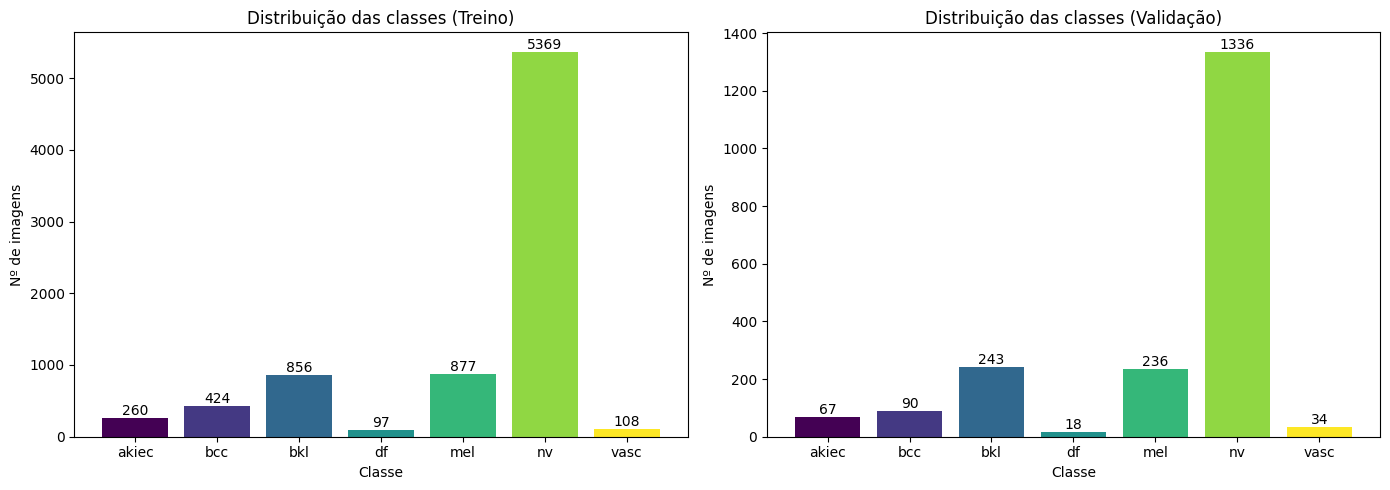

In [6]:
def count_images(folder):
    return {c: len(os.listdir(os.path.join(folder, c))) for c in categories}

train_counts = count_images(train_folder)
val_counts = count_images(val_folder)
print('Treino:', sum(train_counts.values()), '| Validação:', sum(val_counts.values()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.get_cmap('viridis')(np.linspace(0, 1, num_classes))
for ax, counts, title in zip(axes, [train_counts, val_counts], ['Treino', 'Validação']):
    ax.bar(list(counts.keys()), list(counts.values()), color=colors)
    ax.bar_label(ax.containers[0])
    ax.set_title(f'Distribuição das classes ({title})')
    ax.set_xlabel('Classe'); ax.set_ylabel('Nº de imagens')
plt.tight_layout()
plt.show()

## 4. Exemplos de imagens
Mostra uma imagem aleatória de cada classe, para confirmar visualmente que os dados estão corretos e perceber como as classes se parecem.

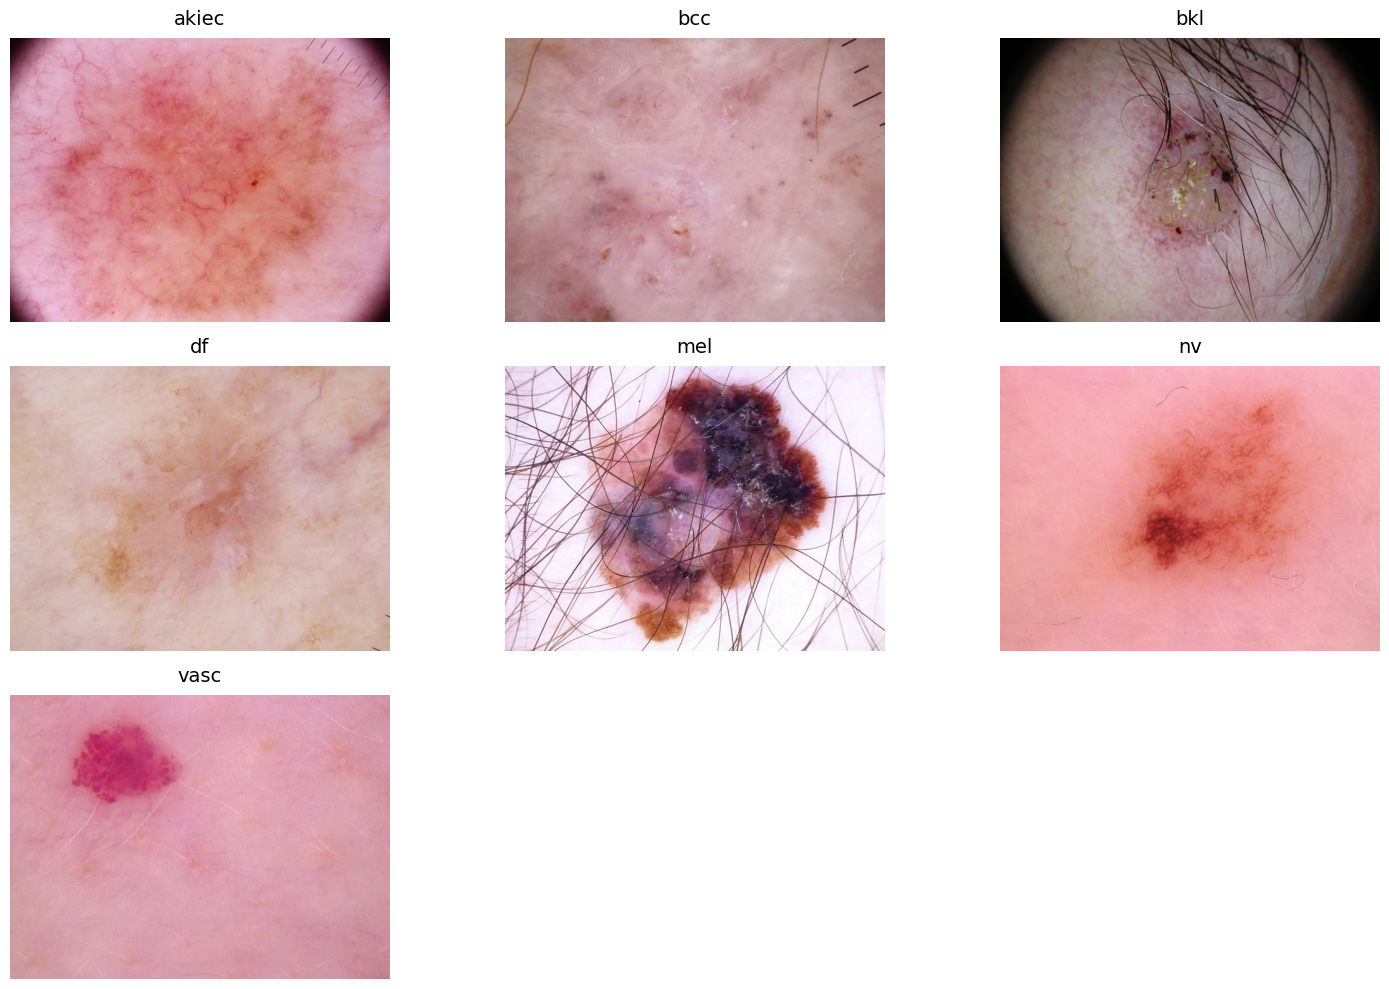

In [7]:
def read_rgb(path):
    # imdecode + fromfile funciona mesmo com caminhos com acentos no Windows
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

fig = plt.figure(figsize=(15, 10))
rows = int(np.ceil(num_classes / 3))
for k, c in enumerate(categories):
    f = random.choice(os.listdir(os.path.join(train_folder, c)))
    ax = fig.add_subplot(rows, 3, k + 1)
    ax.imshow(read_rgb(os.path.join(train_folder, c, f)))
    ax.set_title(c, pad=10, size=14)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Pré-processamento e carregamento dos dados
`load_image` lê e prepara **uma** imagem; `load_split` faz isso para uma pasta inteira; `get_data` junta treino e validação e guarda o resultado em cache. As opções de pré-processamento são parâmetros, para poderes compará-las nas experiências:

| Parâmetro | O que faz |
|---|---|
| `img_size` | Tamanho final (quadrado). Ex.: 128 ou 224. |
| `to_rgb` | Converte de BGR (OpenCV) para RGB, que é o que os pesos do ImageNet esperam. |
| `pad` | Acrescenta margens pretas para tornar a imagem quadrada **antes** de redimensionar, em vez de a esticar. |

**Decisão de memória:** os arrays ficam em `uint8` (0–255), sem dividir por 255. Em `float32` o dataset a 224×224 ocuparia cerca de 6 GB; em `uint8` ocupa cerca de 1,5 GB. A normalização é feita **dentro dos modelos** (o EfficientNet já a inclui; o CNN básico tem uma camada `Rescaling(1/255)`).

In [8]:
def load_image(path, img_size=128, to_rgb=False, pad=False):
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)   # BGR, uint8
    if img is None:
        return None
    if pad:   # tornar quadrada com margens pretas, sem deformar a lesão
        h, w = img.shape[:2]
        s = max(h, w)
        top, left = (s - h) // 2, (s - w) // 2
        img = cv2.copyMakeBorder(img, top, s - h - top, left, s - w - left,
                                 cv2.BORDER_CONSTANT, value=(0, 0, 0))
    img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
    if to_rgb:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

def load_split(folder, img_size=128, to_rgb=False, pad=False):
    X, Y = [], []
    for idx, c in enumerate(categories):
        cdir = os.path.join(folder, c)
        files = sorted(f for f in os.listdir(cdir) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
        if LIMIT_PER_CLASS:
            files = files[:LIMIT_PER_CLASS]
        for f in tqdm(files, desc=f'{os.path.basename(folder)}/{c}', leave=False):
            img = load_image(os.path.join(cdir, f), img_size, to_rgb, pad)
            if img is not None:
                X.append(img)
                Y.append(idx)
    return np.asarray(X, dtype=np.uint8), np.asarray(Y, dtype=np.int64)

_DATA_CACHE = {}
def get_data(img_size=128, to_rgb=False, pad=False):
    key = (img_size, to_rgb, pad, LIMIT_PER_CLASS)
    if key not in _DATA_CACHE:
        _DATA_CACHE.clear()   # só mantém uma configuração em memória
        gc.collect()
        X_tr, Y_tr = load_split(train_folder, img_size, to_rgb, pad)
        X_va, Y_va = load_split(val_folder, img_size, to_rgb, pad)
        _DATA_CACHE[key] = (X_tr, Y_tr, X_va, Y_va)
    return _DATA_CACHE[key]

### 5.1 Carregar a configuração base
Carrega treino e validação com a configuração base (128×128, BGR, sem padding). É também a que o baseline usa. Confirma que as formas e os totais fazem sentido.

In [9]:
X_train, Y_train, X_val, Y_val = get_data(128)
print('X_train:', X_train.shape, X_train.dtype, '| Y_train:', Y_train.shape)
print('X_val  :', X_val.shape, X_val.dtype, '| Y_val  :', Y_val.shape)
print('Intervalo de pixels:', X_train.min(), '-', X_train.max())

X_train: (7991, 128, 128, 3) uint8 | Y_train: (7991,)
X_val  : (2024, 128, 128, 3) uint8 | Y_val  : (2024,)
Intervalo de pixels: 0 - 255


## 6. Funções auxiliares
Reutilizadas em todas as experiências:
- `plot_history` — curvas de accuracy e loss (treino vs validação), para detetar *overfitting*.
- `evaluate_model` — calcula accuracy, **macro F1**, **macro recall** e recall por classe na validação.
- `plot_confusion_matrix` — matriz de confusão (em contagens e normalizada por linha) e relatório de classificação.
- Registo de resultados (`RESULTS`) — guarda uma linha por experiência e grava tudo em `results.csv`, para sobreviver a reinícios do kernel.

In [10]:
def plot_history(history, title):
    h = history.history
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(h['accuracy'], label='train_accuracy')
    plt.plot(h['val_accuracy'], label='val_accuracy')
    plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend()
    plt.title(f'{title} Accuracy Curves')

    plt.subplot(1, 2, 2)
    plt.plot(h['loss'], label='train_loss')
    plt.plot(h['val_loss'], label='val_loss')
    plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend()
    plt.title(f'{title} Loss Curves')

    plt.tight_layout()
    plt.show()

def evaluate_model(model, X, Y):
    probs = model.predict(X, batch_size=64, verbose=0)
    y_pred = probs.argmax(axis=1)
    labels = list(range(num_classes))
    recalls = recall_score(Y, y_pred, labels=labels, average=None, zero_division=0)
    metrics = {
        'accuracy': float((y_pred == Y).mean()),
        'macro_f1': float(f1_score(Y, y_pred, labels=labels, average='macro', zero_division=0)),
        'macro_recall': float(recalls.mean()),
        'val_loss': float(np.mean(tf.keras.losses.sparse_categorical_crossentropy(Y, probs).numpy())),
    }
    for c, r in zip(categories, recalls):
        metrics[f'recall_{c}'] = float(r)
    return metrics

def plot_confusion_matrix(model, X, Y, categories, title):
    y_pred = model.predict(X, batch_size=64, verbose=0).argmax(axis=1)
    labels = list(range(len(categories)))
    cm = confusion_matrix(Y, y_pred, labels=labels)
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=categories, yticklabels=categories, ax=axes[0])
    axes[0].set_title(f'{title} (contagens)')
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=categories, yticklabels=categories,
                vmin=0, vmax=1, ax=axes[1])
    axes[1].set_title(f'{title} (normalizada por linha = recall)')
    for ax in axes:
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.show()

    print("\n Classification Report:\n")
    print(classification_report(Y, y_pred, labels=labels, target_names=categories, zero_division=0))

In [11]:
RESULTS_CSV = 'results.csv'
RESULTS = pd.read_csv(RESULTS_CSV).to_dict('records') if os.path.exists(RESULTS_CSV) else []

MAIN_COLS = ['name', 'variant', 'img_size', 'rgb', 'pad', 'augment', 'class_weights', 'fine_tune',
             'accuracy', 'macro_f1', 'macro_recall', 'recall_mel', 'epochs', 'minutes']

def _save_results():
    pd.DataFrame(RESULTS).to_csv(RESULTS_CSV, index=False)

def add_result(row):
    global RESULTS
    RESULTS = [r for r in RESULTS if r['name'] != row['name']] + [row]   # volta a correr = substitui
    _save_results()

def remove_result(name):
    global RESULTS
    RESULTS = [r for r in RESULTS if r['name'] != name]
    _save_results()

def results_table():
    df = pd.DataFrame(RESULTS)
    if df.empty:
        return df
    return df.sort_values('macro_f1', ascending=False).reset_index(drop=True)

def show_results():
    df = results_table()
    if df.empty:
        print('Ainda não há resultados.')
    else:
        display(df[MAIN_COLS].round(3))

def plot_results():
    df = results_table()
    if df.empty:
        return
    ax = df.set_index('name')[['macro_f1', 'macro_recall', 'recall_mel']].plot.bar(figsize=(12, 5))
    ax.set_title('Comparação de experiências (validação)')
    ax.set_ylim(0, 1); ax.set_ylabel('Métrica'); ax.set_xlabel('')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

def register(name, model, X, Y, cfg, epochs, t0):
    # guarda o modelo, avalia-o e acrescenta uma linha à tabela de resultados
    path = os.path.join(MODELS_DIR, f'{name}.keras')
    model.save(path)
    row = {'name': name, **cfg, **evaluate_model(model, X, Y),
           'epochs': epochs, 'minutes': round((time.time() - t0) / 60, 1), 'model_path': path}
    add_result(row)
    return row

## 7. Baseline — CNN básico
Modelo simples construído de raiz, usado como **referência** para comparar com o EfficientNet. Esta secção é opcional: podes saltá-la sem afetar o resto. Trabalha diretamente sobre os arrays `uint8` da secção 5.1, por isso a primeira camada é um `Rescaling(1/255)`.

No treino anterior (100 épocas, sem *early stopping*) o modelo chegava a accuracy de treino de 1.00 contra ≈ 0.71 em validação, ou seja, overfitting forte. Agora o treino pára sozinho quando a `val_accuracy` deixa de melhorar.

In [12]:
def build_basic_cnn(input_shape, num_classes):
    model = Sequential([
        Input(shape=input_shape),
        Rescaling(1.0 / 255),
        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(num_classes, activation='softmax'),
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

basic_cnn = build_basic_cnn((128, 128, 3), num_classes)
basic_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,223 (28.20 MB)

 Trainable params: 7,393,223 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Treino
Até 50 épocas, com *early stopping* na `val_accuracy` (paciência 10) e recuperação dos melhores pesos.

Epoch 1/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 73ms/step - accuracy: 0.6689 - loss: 0.9935 - val_accuracy: 0.6650 - val_loss: 0.9096
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 18s 72ms/step - accuracy: 0.6874 - loss: 0.8710 - val_accuracy: 0.6803 - val_loss: 0.8422
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 18s 72ms/step - accuracy: 0.7079 - loss: 0.7920 - val_accuracy: 0.6803 - val_loss: 0.8560
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 18s 72ms/step - accuracy: 0.7284 - loss: 0.7276 - val_accuracy: 0.6917 - val_loss: 0.8264
Epoch 5/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 76ms/step - accuracy: 0.7440 - loss: 0.6931 - val_accuracy: 0.6917 - val_loss: 0.8226
Epoch 6/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 75ms/step - accuracy: 0.7560 - loss: 0.6486 - val_accuracy: 0.7036 - val_loss: 0.8420
Epoch 7/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step - accuracy: 0.7725 - loss: 0.6100 - val_accuracy: 0.7144 - val_loss: 0.8243
Epoch 8/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step - accuracy: 0.7851 - loss: 0.5656 - 

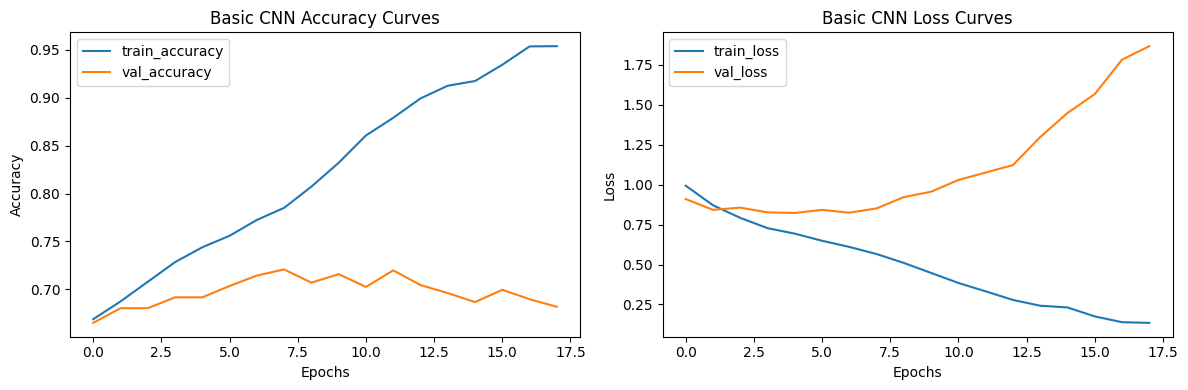

In [13]:
set_seed()
t0 = time.time()
history_cnn = basic_cnn.fit(
    X_train, Y_train, validation_data=(X_val, Y_val),
    epochs=50, batch_size=32,
    callbacks=[EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)],
)
plot_history(history_cnn, 'Basic CNN')

### 7.2 Avaliação e registo
Calcula as métricas na validação, guarda o modelo e acrescenta a linha `CNN_basico` à tabela de resultados.

{'accuracy': 0.721, 'macro_f1': 0.421, 'macro_recall': 0.404, 'recall_mel': 0.178}


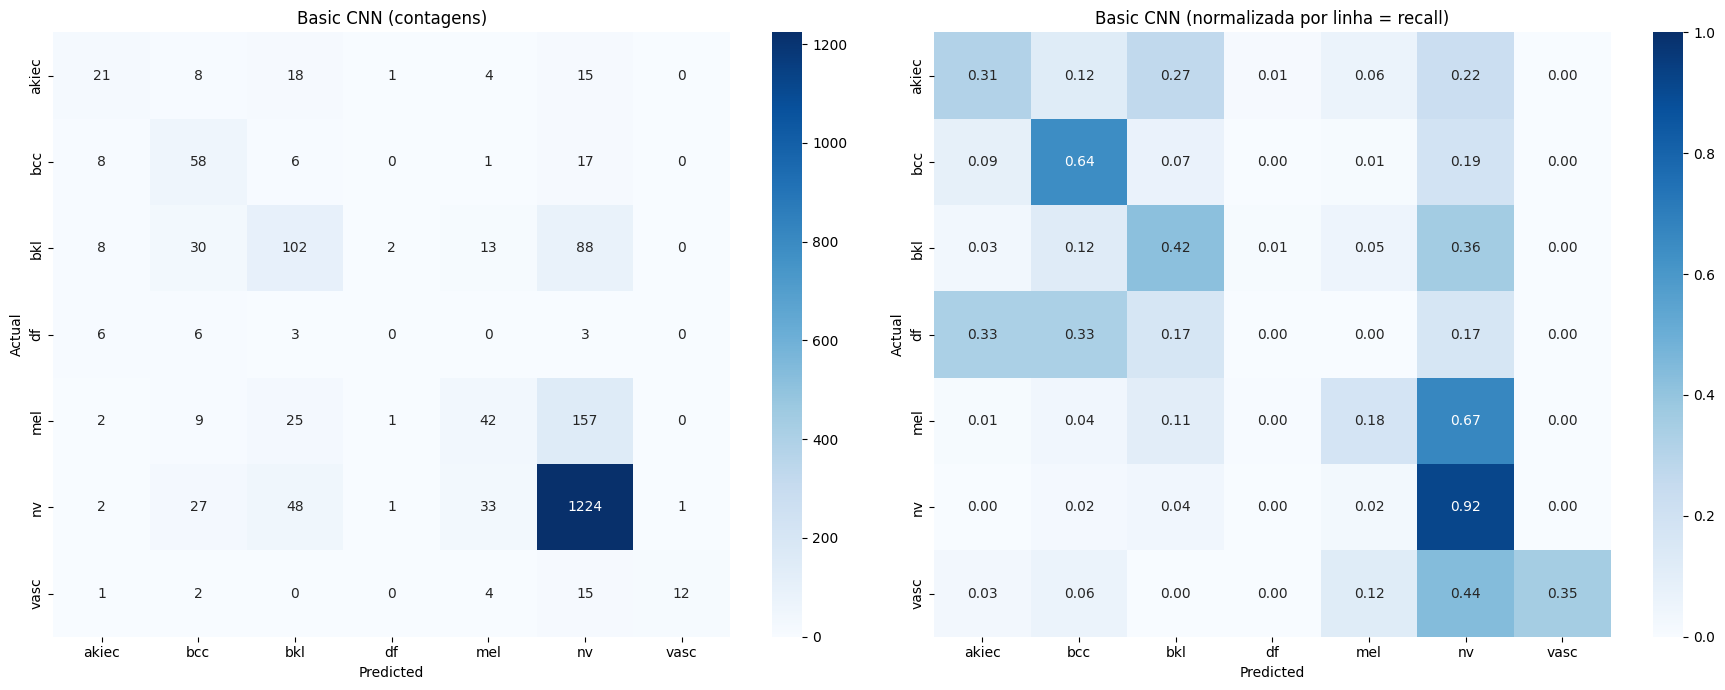


 Classification Report:

              precision    recall  f1-score   support

       akiec       0.44      0.31      0.37        67
         bcc       0.41      0.64      0.50        90
         bkl       0.50      0.42      0.46       243
          df       0.00      0.00      0.00        18
         mel       0.43      0.18      0.25       236
          nv       0.81      0.92      0.86      1336
        vasc       0.92      0.35      0.51        34

    accuracy                           0.72      2024
   macro avg       0.50      0.40      0.42      2024
weighted avg       0.69      0.72      0.69      2024



In [14]:
cfg = dict(variant='CNN', img_size=128, rgb=False, pad=False, augment=False, class_weights='none', fine_tune=False)
row = register('CNN_basico', basic_cnn, X_val, Y_val, cfg, len(history_cnn.history['loss']), t0)
print({k: round(v, 3) for k, v in row.items() if k in ('accuracy', 'macro_f1', 'macro_recall', 'recall_mel')})
plot_confusion_matrix(basic_cnn, X_val, Y_val, categories, 'Basic CNN')

## 8. EfficientNet — construção, treino e fine-tuning
Aqui ficam as funções; as experiências em si estão na secção 9.

**Transfer learning em duas fases:**
1. **Cabeça:** o EfficientNet pré-treinado no ImageNet fica **congelado** e só se treina a cabeça nova (`GlobalMaxPooling2D` → Dense(256) → BatchNorm → Dropout(0.5) → softmax).
2. **Fine-tuning (opcional):** descongelam-se as últimas `ft_layers` camadas do backbone (as `BatchNormalization` ficam sempre congeladas) e treina-se com *learning rate* muito baixa (1e-5). Foi o passo que faltou na primeira experiência, em que o backbone congelado levou a subajuste.

**Outras decisões:**
- **Data augmentation** (flips, rotação, zoom) só atua no treino. Não se alteram cores, porque a cor é informação clínica relevante.
- **Pesos por classe:** `balanced` dá à classe `df` um peso ≈ 50 vezes superior ao de `nv`, o que gerou muitos falsos alarmes. O modo `sqrt` (por defeito) usa a raiz quadrada desses pesos, mais suave.
- O EfficientNet do Keras **já inclui** a normalização de entrada e espera pixels 0–255, que é exatamente o que os arrays `uint8` fornecem.
- *Early stopping* e redução da *learning rate* na `val_loss`; no fim ficam os melhores pesos.

In [15]:
def make_augmentation():
    return Sequential([
        RandomFlip('horizontal_and_vertical'),
        RandomRotation(0.2),
        RandomZoom(0.1),
    ], name='data_augmentation')

def build_efficientnet(variant='B4', img_size=128, augment=True, head_lr=5e-4):
    Base = {'B0': EfficientNetB0, 'B4': EfficientNetB4}[variant]
    base = Base(include_top=False, weights=PRETRAINED, input_shape=(img_size, img_size, 3))
    base.trainable = False   # fase 1: só a cabeça aprende

    inputs = Input(shape=(img_size, img_size, 3))
    x = make_augmentation()(inputs) if augment else inputs
    x = base(x, training=False)
    x = GlobalMaxPooling2D()(x)
    x = Dense(256, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(head_lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model, base

def unfreeze_top_layers(model, base, n_layers=30, lr=1e-5):
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, BatchNormalization):
            layer.trainable = False   # mantém as estatísticas do ImageNet
    model.compile(optimizer=Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def get_class_weights(y, mode='sqrt'):
    assert mode in ('none', 'sqrt', 'balanced')
    if mode == 'none':
        return None
    classes = np.unique(y)
    cw = compute_class_weight('balanced', classes=classes, y=y)
    if mode == 'sqrt':
        cw = np.sqrt(cw)
    return {int(c): float(w) for c, w in zip(classes, cw)}

def merge_history(*hs):
    keys = hs[0].history.keys()
    return SimpleNamespace(history={k: sum((list(h.history[k]) for h in hs), []) for k in keys})

### 8.1 `run_experiment`
Uma única função que faz tudo: carrega os dados com o pré-processamento pedido, constrói o modelo, treina (cabeça + fine-tuning opcional), mostra as curvas, avalia, guarda o modelo e regista uma linha na tabela de resultados. Basta mudar **um parâmetro de cada vez**.

In [16]:
def run_experiment(name, variant='B4', img_size=128, to_rgb=False, pad=False, augment=True,
                   class_weight_mode='sqrt', epochs_head=15, fine_tune=True, epochs_ft=15,
                   ft_layers=30, batch_size=32):
    print(f'\n=== {name} ===')
    tf.keras.backend.clear_session()
    gc.collect()
    set_seed()
    t0 = time.time()

    X_tr, Y_tr, X_va, Y_va = get_data(img_size, to_rgb, pad)
    cw = get_class_weights(Y_tr, class_weight_mode)
    if cw:
        print('Pesos por classe:', {categories[k]: round(v, 2) for k, v in cw.items()})

    def callbacks():
        return [EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, verbose=1)]

    model, base = build_efficientnet(variant, img_size, augment)
    hists = [model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=epochs_head,
                       batch_size=batch_size, class_weight=cw, callbacks=callbacks())]
    if fine_tune:
        unfreeze_top_layers(model, base, ft_layers)
        hists.append(model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=epochs_ft,
                               batch_size=batch_size, class_weight=cw, callbacks=callbacks()))

    history = merge_history(*hists)
    plot_history(history, name)

    cfg = dict(variant=variant, img_size=img_size, rgb=to_rgb, pad=pad, augment=augment,
               class_weights=class_weight_mode, fine_tune=fine_tune)
    row = register(name, model, X_va, Y_va, cfg, len(history.history['loss']), t0)
    print({k: round(v, 3) for k, v in row.items() if k in ('accuracy', 'macro_f1', 'macro_recall', 'recall_mel')},
          f"| {row['minutes']} min")
    return row

## 9. Experiências
**Protocolo:** todas as experiências usam a mesma *seed*, o mesmo split de validação e os mesmos *callbacks*. A **E1 é a referência**; cada uma das seguintes muda **uma única coisa** em relação à E1. Decide pelo **macro F1** e pelo **recall de `mel`**, não pela accuracy.

| Experiência | O que muda face à E1 |
|---|---|
| E1 | Referência: B4, 128×128, BGR, sem padding, com augmentation, pesos `sqrt`, com fine-tuning |
| E2 | Conversão BGR → RGB |
| E3 | Padding (sem deformar a imagem) |
| E4 | Sem data augmentation |
| E5 | Pesos de classe `balanced` (mais agressivos) |
| E6 | Resolução 224×224 (**pesado**) |

### 9.0 Teste rápido do pipeline (recomendado)
Antes das corridas completas, testa o fluxo todo com 30 imagens por classe, o EfficientNetB0 e 1 época. Demora poucos minutos e apanha erros de caminhos, memória ou bibliotecas. No fim, repõe o dataset completo e apaga o teste da tabela.


=== TESTE_RAPIDO ===
Pesos por classe: {'akiec': 1.0, 'bcc': 1.0, 'bkl': 1.0, 'df': 1.0, 'mel': 1.0, 'nv': 1.0, 'vasc': 1.0}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 45s 3us/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 658ms/step - accuracy: 0.1857 - loss: 2.9387 - val_accuracy: 0.1818 - val_loss: 2.4461 - learning_rate: 5.0000e-04


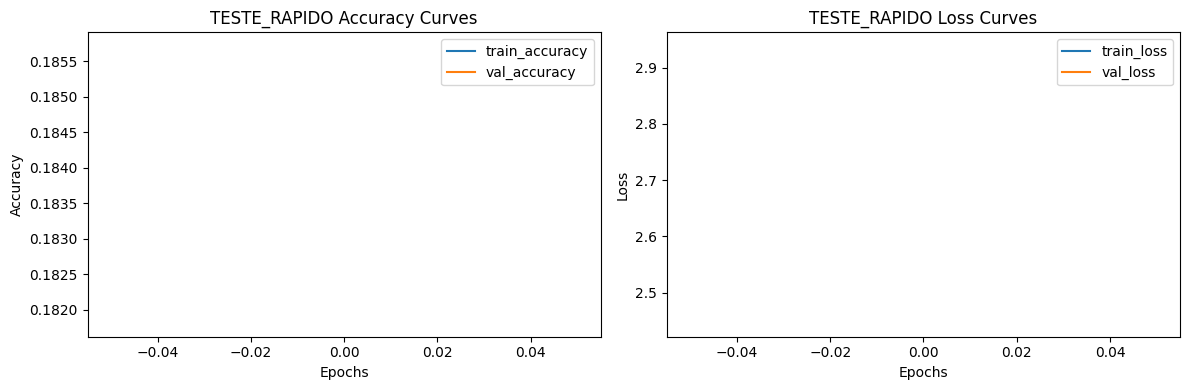

{'accuracy': 0.182, 'macro_f1': 0.158, 'macro_recall': 0.178, 'recall_mel': 0.033} | 1.1 min


In [18]:
LIMIT_PER_CLASS = 30
run_experiment('TESTE_RAPIDO', variant='B0', epochs_head=1, fine_tune=False)

LIMIT_PER_CLASS = None            # IMPORTANTE: voltar ao dataset completo
remove_result('TESTE_RAPIDO')     # tira o teste da tabela de resultados

### 9.1 E1 — Referência
> Dica: se quiseres medir o tempo antes de uma corrida longa, usa `epochs_head=2, epochs_ft=2` numa primeira vez.


=== E1_B4_128_ref ===


Pesos por classe: {'akiec': 2.1, 'bcc': 1.64, 'bkl': 1.15, 'df': 3.43, 'mel': 1.14, 'nv': 0.46, 'vasc': 3.25}
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 111s 382ms/step - accuracy: 0.4396 - loss: 1.5454 - val_accuracy: 0.6630 - val_loss: 0.9906 - learning_rate: 5.0000e-04
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 228s 916ms/step - accuracy: 0.6006 - loss: 1.1937 - val_accuracy: 0.6971 - val_loss: 0.8729 - learning_rate: 5.0000e-04
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 193s 771ms/step - accuracy: 0.6341 - loss: 1.1163 - val_accuracy: 0.6932 - val_loss: 0.8884 - learning_rate: 5.0000e-04
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 109s 433ms/step - accuracy: 0.6418 - loss: 1.0492 - val_accuracy: 0.6927 - val_loss: 0.8482 - learning_rate: 5.0000e-04
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 123s 493ms/step - accuracy: 0.6594 - loss: 1.0128 - val_accuracy: 0.6897 - val_loss: 0.8692 - learning_rate: 5.0000e-04
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 181s 649ms/step - accuracy: 0.6659 - loss: 1.0019 

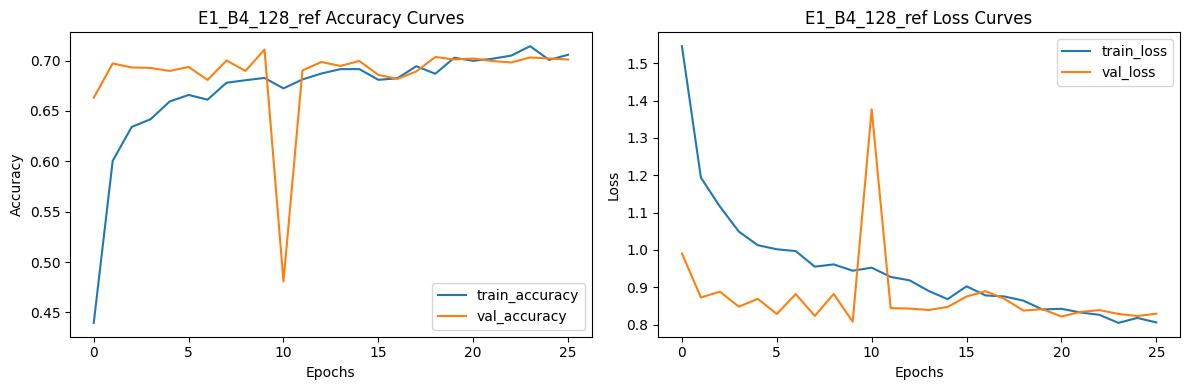

{'accuracy': 0.702, 'macro_f1': 0.417, 'macro_recall': 0.425, 'recall_mel': 0.335} | 118.1 min


{'name': 'E1_B4_128_ref',
 'variant': 'B4',
 'img_size': 128,
 'rgb': False,
 'pad': False,
 'augment': True,
 'class_weights': 'sqrt',
 'fine_tune': True,
 'accuracy': 0.7020750988142292,
 'macro_f1': 0.416690804209657,
 'macro_recall': 0.4254074270683362,
 'val_loss': 0.8219183683395386,
 'recall_akiec': 0.3582089552238806,
 'recall_bcc': 0.26666666666666666,
 'recall_bkl': 0.588477366255144,
 'recall_df': 0.1111111111111111,
 'recall_mel': 0.3347457627118644,
 'recall_nv': 0.8480538922155688,
 'recall_vasc': 0.47058823529411764,
 'epochs': 26,
 'minutes': 118.1,
 'model_path': 'models\\E1_B4_128_ref.keras'}

In [19]:
run_experiment('E1_B4_128_ref')

### 9.2 E2 — Conversão BGR → RGB
O OpenCV lê em BGR, mas os pesos do ImageNet foram treinados com RGB.


=== E2_rgb ===


Pesos por classe: {'akiec': 2.1, 'bcc': 1.64, 'bkl': 1.15, 'df': 3.43, 'mel': 1.14, 'nv': 0.46, 'vasc': 3.25}
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 198s 486ms/step - accuracy: 0.4301 - loss: 1.5491 - val_accuracy: 0.6299 - val_loss: 1.0801 - learning_rate: 5.0000e-04
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 92s 366ms/step - accuracy: 0.5799 - loss: 1.2120 - val_accuracy: 0.6961 - val_loss: 0.8749 - learning_rate: 5.0000e-04
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 139s 356ms/step - accuracy: 0.6159 - loss: 1.1421 - val_accuracy: 0.6897 - val_loss: 0.8623 - learning_rate: 5.0000e-04
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 90s 361ms/step - accuracy: 0.6368 - loss: 1.0757 - val_accuracy: 0.6611 - val_loss: 1.0000 - learning_rate: 5.0000e-04
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 85s 339ms/step - accuracy: 0.6480 - loss: 1.0344 - val_accuracy: 0.7060 - val_loss: 0.8517 - learning_rate: 5.0000e-04
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 84s 337ms/step - accuracy: 0.6547 - loss: 1.0083 - va

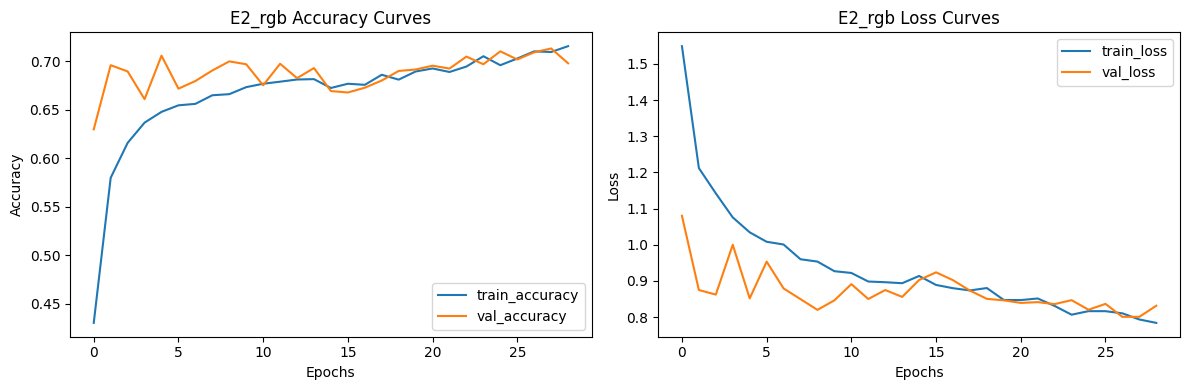

{'accuracy': 0.709, 'macro_f1': 0.473, 'macro_recall': 0.493, 'recall_mel': 0.407} | 55.9 min


{'name': 'E2_rgb',
 'variant': 'B4',
 'img_size': 128,
 'rgb': True,
 'pad': False,
 'augment': True,
 'class_weights': 'sqrt',
 'fine_tune': True,
 'accuracy': 0.7094861660079052,
 'macro_f1': 0.4733345837543306,
 'macro_recall': 0.49275046955892765,
 'val_loss': 0.8006606101989746,
 'recall_akiec': 0.43283582089552236,
 'recall_bcc': 0.35555555555555557,
 'recall_bkl': 0.5432098765432098,
 'recall_df': 0.16666666666666666,
 'recall_mel': 0.4067796610169492,
 'recall_nv': 0.8383233532934131,
 'recall_vasc': 0.7058823529411765,
 'epochs': 29,
 'minutes': 55.9,
 'model_path': 'models\\E2_rgb.keras'}

In [20]:
run_experiment('E2_rgb', to_rgb=True)

### 9.3 E3 — Padding em vez de esticar
Torna a imagem quadrada com margens pretas antes de redimensionar, para não deformar as lesões.


=== E3_pad ===


Pesos por classe: {'akiec': 2.1, 'bcc': 1.64, 'bkl': 1.15, 'df': 3.43, 'mel': 1.14, 'nv': 0.46, 'vasc': 3.25}
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 119s 414ms/step - accuracy: 0.3604 - loss: 1.7271 - val_accuracy: 0.5776 - val_loss: 1.2257 - learning_rate: 5.0000e-04
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 94s 376ms/step - accuracy: 0.5255 - loss: 1.3932 - val_accuracy: 0.6591 - val_loss: 0.9736 - learning_rate: 5.0000e-04
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 95s 380ms/step - accuracy: 0.5855 - loss: 1.2585 - val_accuracy: 0.6690 - val_loss: 0.9680 - learning_rate: 5.0000e-04
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 97s 388ms/step - accuracy: 0.5988 - loss: 1.2094 - val_accuracy: 0.6537 - val_loss: 0.9461 - learning_rate: 5.0000e-04
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 94s 374ms/step - accuracy: 0.6072 - loss: 1.1713 - val_accuracy: 0.6779 - val_loss: 1.0269 - learning_rate: 5.0000e-04
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.6154 - loss: 1.1539
Epoch 

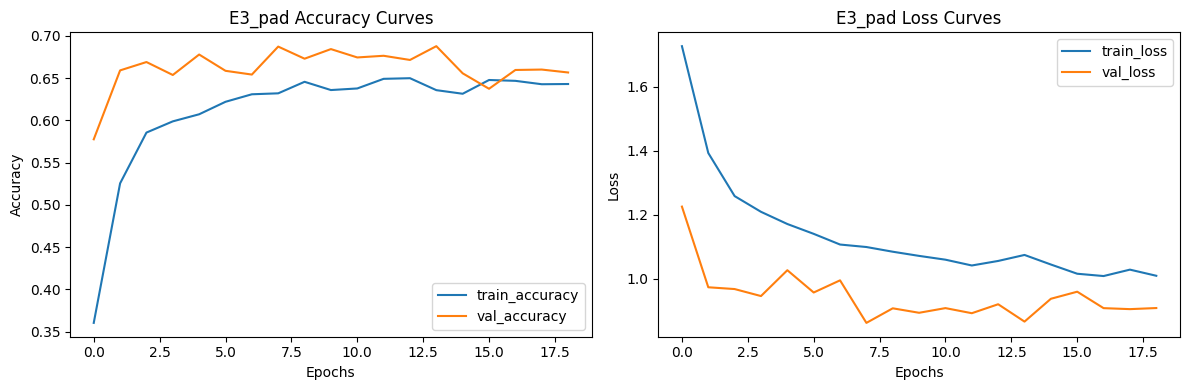

{'accuracy': 0.688, 'macro_f1': 0.4, 'macro_recall': 0.393, 'recall_mel': 0.47} | 34.3 min


{'name': 'E3_pad',
 'variant': 'B4',
 'img_size': 128,
 'rgb': False,
 'pad': True,
 'augment': True,
 'class_weights': 'sqrt',
 'fine_tune': True,
 'accuracy': 0.6877470355731226,
 'macro_f1': 0.40031272553442526,
 'macro_recall': 0.3930525723760824,
 'val_loss': 0.8663111329078674,
 'recall_akiec': 0.1791044776119403,
 'recall_bcc': 0.3111111111111111,
 'recall_bkl': 0.39094650205761317,
 'recall_df': 0.05555555555555555,
 'recall_mel': 0.4703389830508475,
 'recall_nv': 0.844311377245509,
 'recall_vasc': 0.5,
 'epochs': 19,
 'minutes': 34.3,
 'model_path': 'models\\E3_pad.keras'}

In [21]:
run_experiment('E3_pad', pad=True)

### 9.4 E4 — Sem data augmentation
Mostra quanto a augmentation contribui.


=== E4_sem_aug ===


Pesos por classe: {'akiec': 2.1, 'bcc': 1.64, 'bkl': 1.15, 'df': 3.43, 'mel': 1.14, 'nv': 0.46, 'vasc': 3.25}
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 127s 438ms/step - accuracy: 0.4224 - loss: 1.5410 - val_accuracy: 0.6863 - val_loss: 0.9242 - learning_rate: 5.0000e-04
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 102s 407ms/step - accuracy: 0.5929 - loss: 1.1577 - val_accuracy: 0.6986 - val_loss: 0.8183 - learning_rate: 5.0000e-04
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 96s 386ms/step - accuracy: 0.6479 - loss: 1.0531 - val_accuracy: 0.6976 - val_loss: 0.8371 - learning_rate: 5.0000e-04
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 95s 379ms/step - accuracy: 0.6640 - loss: 0.9736 - val_accuracy: 0.7149 - val_loss: 0.7691 - learning_rate: 5.0000e-04
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 95s 378ms/step - accuracy: 0.6806 - loss: 0.9148 - val_accuracy: 0.7041 - val_loss: 0.8183 - learning_rate: 5.0000e-04
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step - accuracy: 0.6759 - loss: 0.9121
Epoch

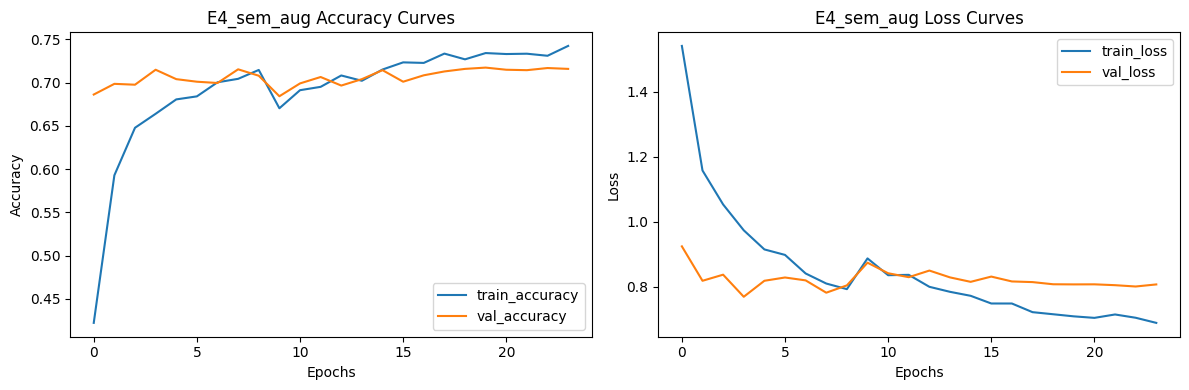

{'accuracy': 0.717, 'macro_f1': 0.456, 'macro_recall': 0.487, 'recall_mel': 0.415} | 46.9 min


{'name': 'E4_sem_aug',
 'variant': 'B4',
 'img_size': 128,
 'rgb': False,
 'pad': False,
 'augment': False,
 'class_weights': 'sqrt',
 'fine_tune': True,
 'accuracy': 0.716897233201581,
 'macro_f1': 0.45644170451568433,
 'macro_recall': 0.48652391523673344,
 'val_loss': 0.8007116317749023,
 'recall_akiec': 0.373134328358209,
 'recall_bcc': 0.4666666666666667,
 'recall_bkl': 0.5185185185185185,
 'recall_df': 0.2222222222222222,
 'recall_mel': 0.4152542372881356,
 'recall_nv': 0.8510479041916168,
 'recall_vasc': 0.5588235294117647,
 'epochs': 24,
 'minutes': 46.9,
 'model_path': 'models\\E4_sem_aug.keras'}

In [22]:
run_experiment('E4_sem_aug', augment=False)

### 9.5 E5 — Pesos de classe `balanced`
Pesos mais agressivos (os que usaste na primeira experiência), para comparar com `sqrt`.


=== E5_cw_balanced ===
Pesos por classe: {'akiec': 4.39, 'bcc': 2.69, 'bkl': 1.33, 'df': 11.77, 'mel': 1.3, 'nv': 0.21, 'vasc': 10.57}
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 129s 457ms/step - accuracy: 0.2749 - loss: 2.0700 - val_accuracy: 0.4788 - val_loss: 1.4513 - learning_rate: 5.0000e-04
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 115s 459ms/step - accuracy: 0.3765 - loss: 1.7186 - val_accuracy: 0.4876 - val_loss: 1.3421 - learning_rate: 5.0000e-04
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 111s 444ms/step - accuracy: 0.4091 - loss: 1.6248 - val_accuracy: 0.4753 - val_loss: 1.4195 - learning_rate: 5.0000e-04
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 114s 456ms/step - accuracy: 0.4359 - loss: 1.5240 - val_accuracy: 0.5440 - val_loss: 1.2441 - learning_rate: 5.0000e-04
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 109s 434ms/step - accuracy: 0.4660 - loss: 1.4424 - val_accuracy: 0.6067 - val_loss: 1.0986 - learning_rate: 5.0000e-04
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 118s 473ms/step - accura

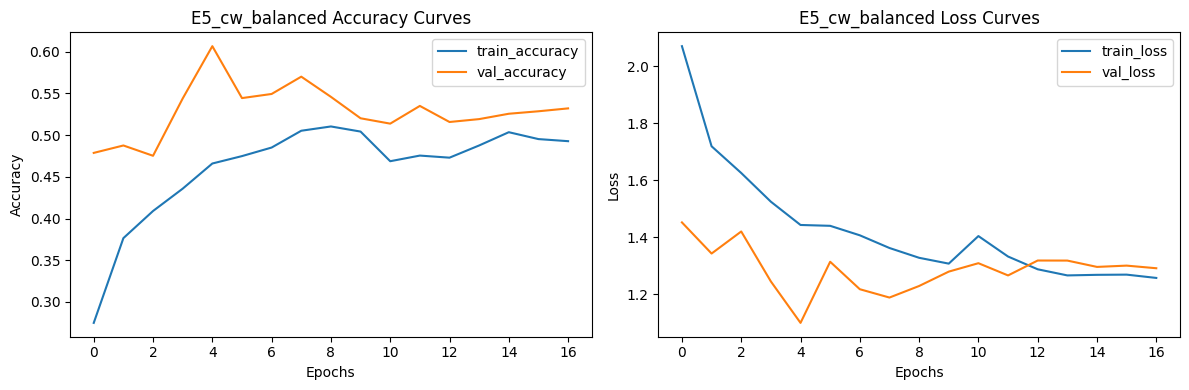

{'accuracy': 0.535, 'macro_f1': 0.341, 'macro_recall': 0.465, 'recall_mel': 0.428} | 34.8 min


{'name': 'E5_cw_balanced',
 'variant': 'B4',
 'img_size': 128,
 'rgb': False,
 'pad': False,
 'augment': True,
 'class_weights': 'balanced',
 'fine_tune': True,
 'accuracy': 0.5350790513833992,
 'macro_f1': 0.34117336653329894,
 'macro_recall': 0.4647675802976314,
 'val_loss': 1.2652250528335571,
 'recall_akiec': 0.43283582089552236,
 'recall_bcc': 0.28888888888888886,
 'recall_bkl': 0.4773662551440329,
 'recall_df': 0.2777777777777778,
 'recall_mel': 0.4279661016949153,
 'recall_nv': 0.5838323353293413,
 'recall_vasc': 0.7647058823529411,
 'epochs': 17,
 'minutes': 34.8,
 'model_path': 'models\\E5_cw_balanced.keras'}

In [23]:
run_experiment('E5_cw_balanced', class_weight_mode='balanced')

### 9.6 E6 — Resolução 224×224
Provavelmente a que mais pesa, porque a 128 o mapa de características final do B4 é só 4×4. Mas é **pesada**: ≈ 1,5 GB de RAM só para as imagens e várias vezes mais tempo por época. Recomenda-se o Colab com GPU. Alternativa mais leve: `variant='B0'`.


=== E6_224 ===


Pesos por classe: {'akiec': 2.1, 'bcc': 1.64, 'bkl': 1.15, 'df': 3.43, 'mel': 1.14, 'nv': 0.46, 'vasc': 3.25}
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 1089s 4s/step - accuracy: 0.4589 - loss: 1.5043 - val_accuracy: 0.6092 - val_loss: 1.2285 - learning_rate: 5.0000e-04
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 243s 970ms/step - accuracy: 0.6078 - loss: 1.1657 - val_accuracy: 0.7011 - val_loss: 0.8512 - learning_rate: 5.0000e-04
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 256s 1s/step - accuracy: 0.6378 - loss: 1.0756 - val_accuracy: 0.6621 - val_loss: 0.9647 - learning_rate: 5.0000e-04
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 819ms/step - accuracy: 0.6558 - loss: 1.0041
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
250/250 ━━━━━━━━━━━━━━━━━━━━ 254s 1s/step - accuracy: 0.6621 - loss: 1.0015 - val_accuracy: 0.6803 - val_loss: 0.8638 - learning_rate: 5.0000e-04
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 246s 985ms/step - accuracy: 0.6691 - loss: 0.9515 - val_accuracy:

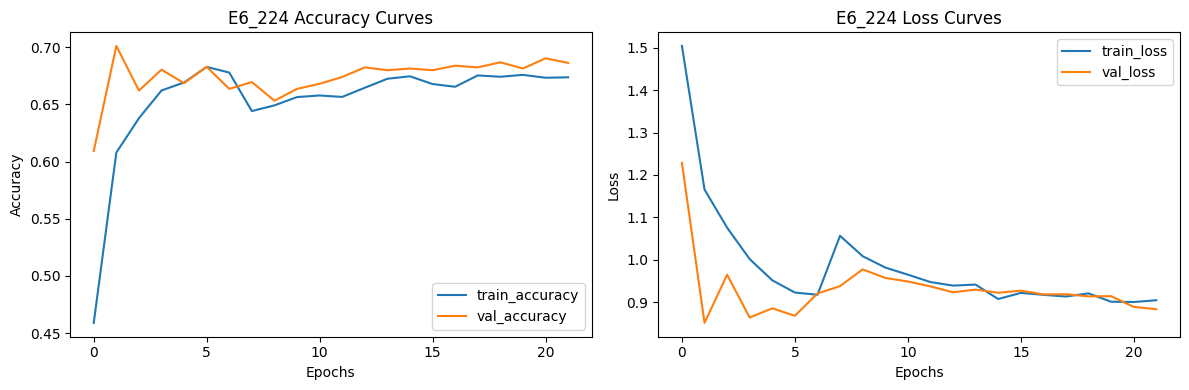

{'accuracy': 0.686, 'macro_f1': 0.44, 'macro_recall': 0.476, 'recall_mel': 0.441} | 127.7 min


{'name': 'E6_224',
 'variant': 'B4',
 'img_size': 224,
 'rgb': False,
 'pad': False,
 'augment': True,
 'class_weights': 'sqrt',
 'fine_tune': True,
 'accuracy': 0.6862648221343873,
 'macro_f1': 0.4402483059372013,
 'macro_recall': 0.475997538984562,
 'val_loss': 0.8834375143051147,
 'recall_akiec': 0.2835820895522388,
 'recall_bcc': 0.34444444444444444,
 'recall_bkl': 0.5596707818930041,
 'recall_df': 0.16666666666666666,
 'recall_mel': 0.4406779661016949,
 'recall_nv': 0.8016467065868264,
 'recall_vasc': 0.7352941176470589,
 'epochs': 22,
 'minutes': 127.7,
 'model_path': 'models\\E6_224.keras'}

In [24]:
run_experiment('E6_224', img_size=224)

## 10. Comparação de resultados
Tabela ordenada por **macro F1** (média do F1 de todas as classes, que dá o mesmo peso às classes raras) e gráfico com macro F1, macro recall e recall de `mel`. Os resultados ficam também em `results.csv`.

> Nota: as métricas são calculadas na pasta de validação, que também é usada para escolher o melhor modelo (via *early stopping* e comparação de experiências). Isto torna os números ligeiramente **otimistas**, e diferenças pequenas (1–2 pontos) podem ser só ruído, sobretudo em classes pequenas como `df` (18 imagens). Para um resultado final rigoroso, deve reservar-se um conjunto de teste à parte.

,name,variant,img_size,rgb,pad,augment,class_weights,fine_tune,accuracy,macro_f1,macro_recall,recall_mel,epochs,minutes
0,E2_rgb,B4,128,True,False,True,sqrt,True,0.709,0.473,0.493,0.407,29,55.9
1,E4_sem_aug,B4,128,False,False,False,sqrt,True,0.717,0.456,0.487,0.415,24,46.9
2,E6_224,B4,224,False,False,True,sqrt,True,0.686,0.440,0.476,0.441,22,127.7
3,CNN_basico,CNN,128,False,False,False,none,False,0.721,0.421,0.404,0.178,18,5.7
4,E1_B4_128_ref,B4,128,False,False,True,sqrt,True,0.702,0.417,0.425,0.335,26,118.1
5,E3_pad,B4,128,False,True,True,sqrt,True,0.688,0.400,0.393,0.470,19,34.3
6,E5_cw_balanced,B4,128,False,False,True,balanced,True,0.535,0.341,0.465,0.428,17,34.8


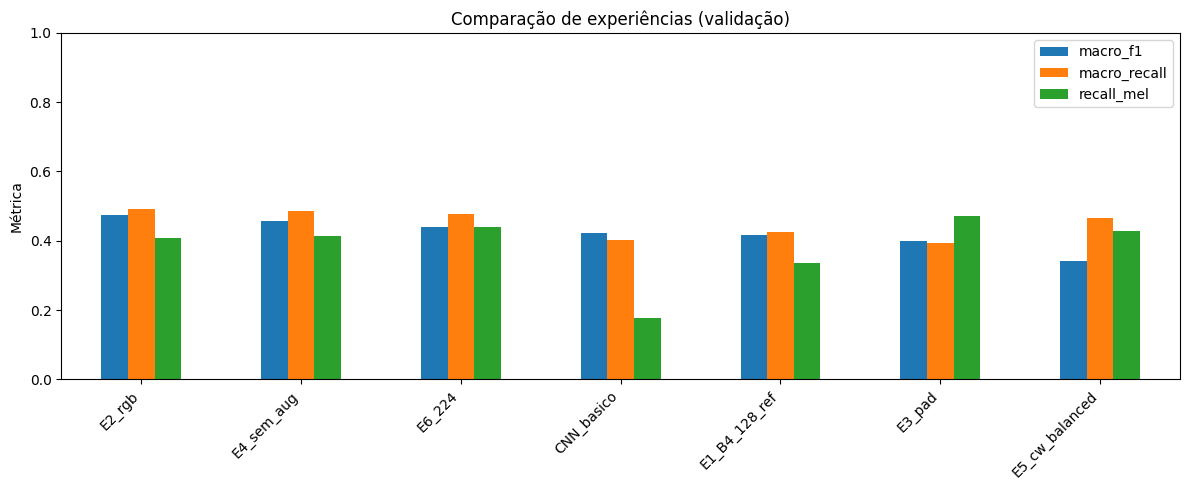

In [25]:
show_results()
plot_results()

## 11. Análise do melhor modelo
Carrega o modelo com maior macro F1, volta a preparar a validação **com o mesmo pré-processamento** com que ele foi treinado e mostra a matriz de confusão e o relatório de classificação.

name               E2_rgb
variant                B4
img_size              128
rgb                  True
pad                 False
augment              True
class_weights        sqrt
fine_tune            True
accuracy         0.709486
macro_f1         0.473335
macro_recall      0.49275
recall_mel        0.40678
epochs                 29
minutes              55.9


Exception ignored in: <function AtomicFunction.__del__ at 0x0000012C55BAE560>
Traceback (most recent call last):
  File "c:\Users\annad\AppData\Local\Programs\Python\Python310\lib\site-packages\tensorflow\python\eager\polymorphic_function\atomic_function.py", line 302, in __del__
    self._bound_context.remove_function(self.name)
KeyboardInterrupt: 


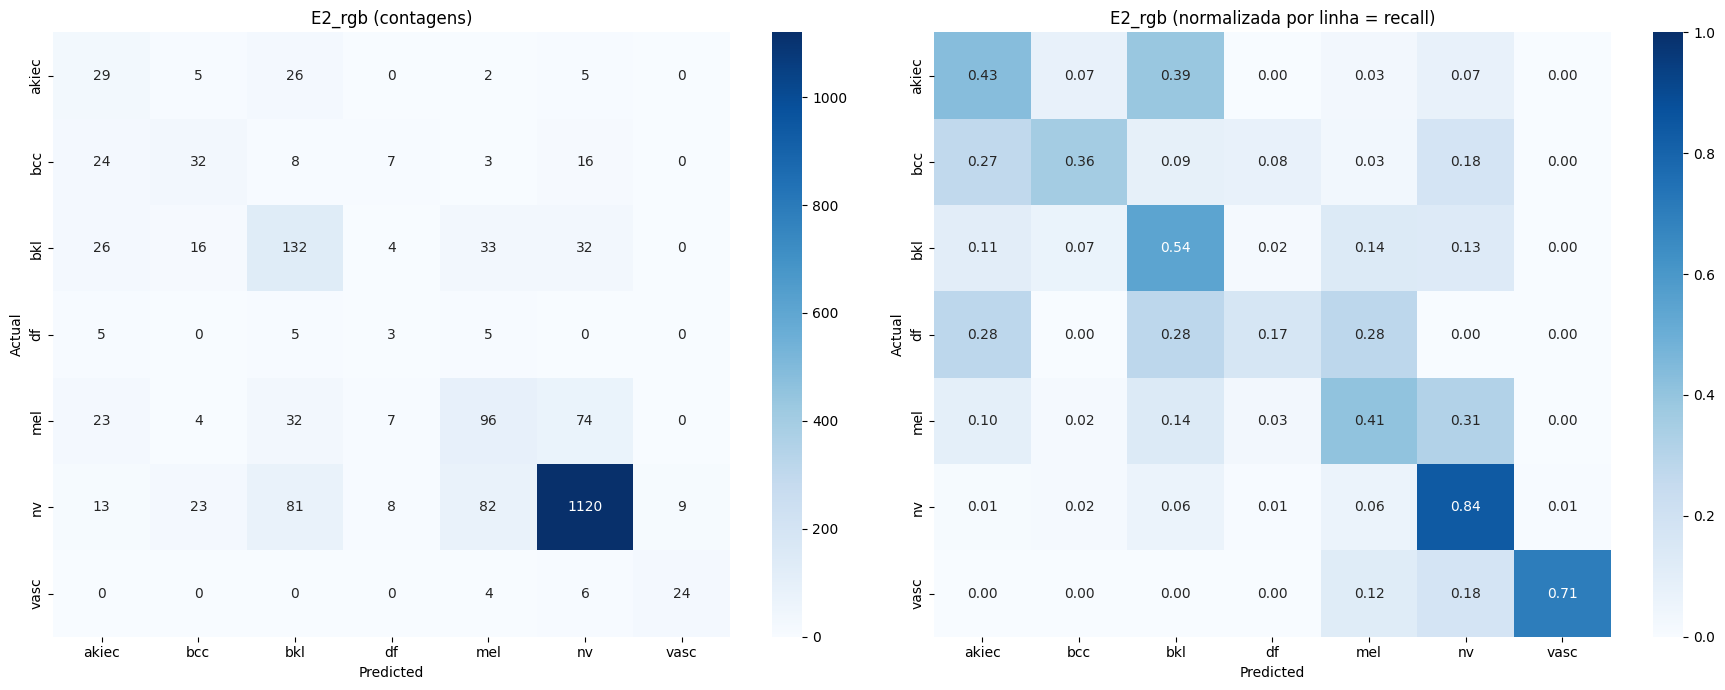


 Classification Report:

              precision    recall  f1-score   support

       akiec       0.24      0.43      0.31        67
         bcc       0.40      0.36      0.38        90
         bkl       0.46      0.54      0.50       243
          df       0.10      0.17      0.13        18
         mel       0.43      0.41      0.42       236
          nv       0.89      0.84      0.87      1336
        vasc       0.73      0.71      0.72        34

    accuracy                           0.71      2024
   macro avg       0.47      0.49      0.47      2024
weighted avg       0.73      0.71      0.72      2024



In [26]:
best = results_table().iloc[0]
print(best[MAIN_COLS].to_string())

best_cfg = dict(img_size=int(best['img_size']), to_rgb=bool(best['rgb']), pad=bool(best['pad']))
best_model = tf.keras.models.load_model(best['model_path'])
_, _, X_v, Y_v = get_data(**best_cfg)
plot_confusion_matrix(best_model, X_v, Y_v, categories, str(best['name']))

## 12. Previsão numa imagem individual
Escolhe uma imagem aleatória da pasta de validação (de uma classe à escolha, ou aleatória), aplica **o mesmo pré-processamento do melhor modelo**, e mostra a imagem com as 3 classes mais prováveis.

> As percentagens vêm do *softmax* e **não são probabilidades calibradas**: um modelo pode estar errado com confiança alta.

Real Class: akiec
  akiec   76.3%
  bkl     18.8%
  bcc      2.6%


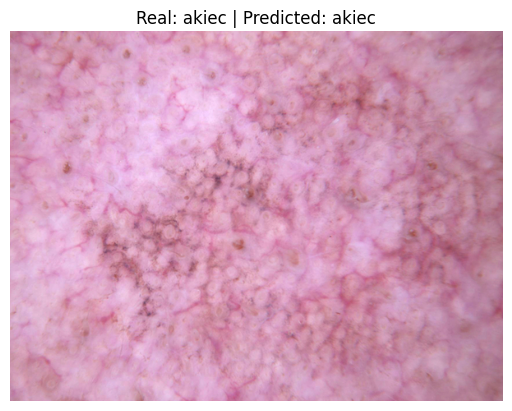

In [30]:
def predict_random_image(model, cfg, classe=None, top_k=3):
    classe = classe or random.choice(categories)
    cdir = os.path.join(val_folder, classe)
    path = os.path.join(cdir, random.choice(os.listdir(cdir)))

    img = load_image(path, cfg['img_size'], cfg['to_rgb'], cfg['pad'])
    probs = model.predict(img[None, ...], verbose=0)[0]
    top = np.argsort(probs)[::-1][:top_k]

    print('Real Class:', classe)
    for i in top:
        print(f'  {categories[i]:<6} {probs[i] * 100:5.1f}%')

    plt.imshow(read_rgb(path))
    plt.title(f'Real: {classe} | Predicted: {categories[top[0]]}')
    plt.axis('off')
    plt.show()

predict_random_image(best_model, best_cfg)               # classe aleatória
# predict_random_image(best_model, best_cfg, classe='mel')   # ou escolhe uma classe

## 13. Classificação hierárquica: melanoma vs. não-melanoma → 6 classes
Até aqui cada modelo decidia **de uma vez** entre as 7 classes. Nesta secção a decisão é feita **em duas etapas** (uma *cascata*):

```
imagem ──► Etapa 1: EfficientNet BINÁRIO ──► P(mel) ≥ limiar?
                                               ├─ sim ──► "mel"
                                               └─ não ──► Etapa 2: EfficientNet de 6 classes ──► akiec, bcc, bkl, df, nv ou vasc
```

- **Etapa 1 (binária):** `mel` contra todas as outras (`akiec, bcc, bkl, df, nv, vasc` juntas). Treina com **todas** as imagens. Saída: probabilidade de melanoma (sigmoide).
- **Etapa 2 (6 classes):** só vê imagens **não-melanoma** (nunca vê um melanoma, nem no treino nem na validação). Só é usada para as imagens que a etapa 1 considera não-melanoma.
- O **limiar** da etapa 1 controla o compromisso entre apanhar mais melanomas (sensibilidade) e gerar menos falsos alarmes.

**Porque pode fazer sentido:** o melanoma é a classe clinicamente mais importante, e uma etapa dedicada concentra toda a capacidade do modelo nessa decisão. Também permite escolher o limiar, o que o modelo de 7 classes não permite. **Mas não há garantia de que melhore**, por isso é uma hipótese a testar contra o modelo plano.

**Cuidados na interpretação**
- **Propagação de erros:** um melanoma que a etapa 1 deixe passar vai para a etapa 2, que não conhece a classe `mel` e atribui-lhe necessariamente uma das outras 6 (erro garantido). E um não-melanoma sinalizado como `mel` também é erro.
- Por isso há **três avaliações**: etapa 1 sozinha, etapa 2 sozinha (nas imagens realmente não-melanoma, o "roteamento perfeito") e a **cascata completa em 7 classes**, que é a única comparável com os modelos planos.
- O limiar é escolhido **na validação**, a mesma onde se avalia: os números da cascata ficam um pouco otimistas. Para comparar com justiça, o notebook mostra também o varrimento de limiares.
- Treinam-se **dois** modelos EfficientNet, por isso uma corrida demora cerca de o dobro de uma experiência normal.

Esta secção **não altera** nenhuma célula anterior nem os resultados já guardados: usa funções com nomes próprios e guarda os seus resultados à parte (`results_hier.csv`).

### 13.1 Etiquetas das duas etapas
- Etapa 1: `1` = melanoma, `0` = não-melanoma (todas as outras classes juntas).
- Etapa 2: só as imagens não-melanoma, com etiquetas `0..5` na ordem alfabética das 6 classes restantes.

In [ ]:
import json
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

MEL = categories.index('mel')
NONMEL_IDX = [i for i, c in enumerate(categories) if c != 'mel']     # índices originais das 6 classes restantes
NONMEL_NAMES = [categories[i] for i in NONMEL_IDX]
_LUT = np.full(len(categories), -1, dtype=np.int64)
_LUT[NONMEL_IDX] = np.arange(len(NONMEL_IDX))                       # índice original -> índice na etapa 2

def split_stage_labels(X, Y):
    Y1 = (Y == MEL).astype(np.int64)      # etapa 1: 1 = melanoma, 0 = não-melanoma
    keep = Y != MEL
    return Y1, X[keep], _LUT[Y[keep]]     # etapa 2: só imagens não-melanoma, etiquetas 0..5

print('Etapa 1: mel (1) vs não-mel (0)')
print('Etapa 2:', NONMEL_NAMES)

### 13.2 Modelos e treino de uma etapa
`build_stage_model` é igual ao EfficientNet das secções anteriores, mas a camada final depende da etapa: **1 neurónio com sigmoide** (binário, perda `binary_crossentropy`, com a métrica AUC) ou **6 neurónios com softmax** (perda `sparse_categorical_crossentropy`). `train_stage` faz o treino em duas fases (cabeça + fine-tuning), como em `run_experiment`, com pesos por classe para compensar o desbalanceamento (mel ≈ 11% na etapa 1; `nv` ≈ 75% dos não-melanoma na etapa 2).

In [ ]:
def _compile_stage(model, lr, binary):
    if binary:
        model.compile(optimizer=Adam(lr), loss='binary_crossentropy',
                      metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    else:
        model.compile(optimizer=Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def build_stage_model(n_out, binary, variant='B4', img_size=128, augment=True, head_lr=5e-4):
    Base = {'B0': EfficientNetB0, 'B4': EfficientNetB4}[variant]
    base = Base(include_top=False, weights=PRETRAINED, input_shape=(img_size, img_size, 3))
    base.trainable = False   # fase 1: só a cabeça aprende

    inputs = Input(shape=(img_size, img_size, 3))
    x = make_augmentation()(inputs) if augment else inputs
    x = base(x, training=False)
    x = GlobalMaxPooling2D()(x)
    x = Dense(256, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    outputs = Dense(1, activation='sigmoid')(x) if binary else Dense(n_out, activation='softmax')(x)

    model = Model(inputs, outputs)
    _compile_stage(model, head_lr, binary)
    return model, base

def unfreeze_stage(model, base, binary, n_layers=30, lr=1e-5):
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, BatchNormalization):
            layer.trainable = False   # mantém as estatísticas do ImageNet
    _compile_stage(model, lr, binary)

def train_stage(tag, X_tr, Y_tr, X_va, Y_va, binary, n_out, variant, img_size, augment, cw_mode,
                epochs_head, fine_tune, epochs_ft, ft_layers, batch_size):
    cw = get_class_weights(Y_tr, cw_mode)
    if cw:
        print('Pesos por classe:', {k: round(v, 2) for k, v in cw.items()})

    def callbacks():
        return [EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, verbose=1)]

    model, base = build_stage_model(n_out, binary, variant, img_size, augment)
    hists = [model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=epochs_head,
                       batch_size=batch_size, class_weight=cw, callbacks=callbacks())]
    if fine_tune:
        unfreeze_stage(model, base, binary, ft_layers)
        hists.append(model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=epochs_ft,
                               batch_size=batch_size, class_weight=cw, callbacks=callbacks()))
    history = merge_history(*hists)
    plot_history(history, tag)
    return model, history

### 13.3 Avaliação das etapas e da cascata
- `binary_metrics` / `choose_threshold` / `plot_stage1`: métricas da etapa 1 (sensibilidade = recall de `mel`, especificidade, precisão, AUC, curvas ROC e Precision-Recall, matriz 2×2). O limiar pode ser escolhido por `'f1'` (maximiza o F1 de `mel`), por `'sensitivity'` (o limiar mais alto que ainda garante `min_sensitivity`, ou seja, prioriza **não falhar melanomas**) ou fixo (por exemplo `0.5`).
- `show_confusion`: matriz de confusão (contagens e normalizada por linha) e relatório de classificação para qualquer conjunto de classes.
- `cascade_predict`: aplica a regra da cascata (`P(mel) ≥ limiar` → `mel`; senão, a classe mais provável da etapa 2).
- `sweep_cascade` / `plot_sweep`: refaz a avaliação da cascata para vários limiares, para ver o compromisso.

In [ ]:
def binary_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); prec = tp / max(tp + fp, 1)
    f1 = 2 * prec * sens / (prec + sens) if (prec + sens) > 0 else 0.0
    return dict(thr=float(thr), sensitivity=sens, specificity=spec, precision=prec, f1=f1,
                balanced_acc=(sens + spec) / 2, accuracy=(tp + tn) / len(y), tp=tp, fp=fp, fn=fn, tn=tn)

def choose_threshold(y, p, mode='f1', min_sensitivity=0.85):
    if isinstance(mode, (int, float)):
        return float(mode)                                   # limiar fixo
    ts = np.linspace(0.01, 0.99, 99)
    ms = [binary_metrics(y, p, t) for t in ts]
    if mode == 'f1':
        return float(ts[int(np.argmax([m['f1'] for m in ms]))])
    if mode == 'sensitivity':
        ok = [t for t, m in zip(ts, ms) if m['sensitivity'] >= min_sensitivity]
        return float(max(ok)) if ok else float(ts[0])         # o mais alto que ainda cumpre a sensibilidade
    raise ValueError("thr_mode: 'f1', 'sensitivity' ou um número")

def plot_stage1(y, p, thr, title):
    fpr, tpr, _ = roc_curve(y, p)
    prec, rec, _ = precision_recall_curve(y, p)
    m = binary_metrics(y, p, thr)
    cm = np.array([[m['tn'], m['fp']], [m['fn'], m['tp']]])
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    axes[0].plot(fpr, tpr)
    axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
    axes[0].scatter([1 - m['specificity']], [m['sensitivity']], color='red', zorder=3, label=f'limiar {thr:.2f}')
    axes[0].set(xlabel='1 − especificidade', ylabel='sensibilidade (recall de mel)',
                title=f'ROC (AUC = {roc_auc_score(y, p):.3f})')
    axes[0].legend(loc='lower right')
    axes[1].plot(rec, prec)
    axes[1].axhline(y.mean(), color='k', ls='--', lw=0.8, label='acaso (prevalência)')
    axes[1].scatter([m['sensitivity']], [m['precision']], color='red', zorder=3, label=f'limiar {thr:.2f}')
    axes[1].set(xlabel='recall (mel)', ylabel='precisão (mel)',
                title=f'Precision-Recall (AP = {average_precision_score(y, p):.3f})')
    axes[1].legend(loc='upper right')
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[2],
                xticklabels=['não-mel', 'mel'], yticklabels=['não-mel', 'mel'])
    axes[2].set(xlabel='Predicted', ylabel='Actual', title=f'Matriz de confusão (limiar {thr:.2f})')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def show_confusion(Y, y_pred, names, title):
    labels = list(range(len(names)))
    cm = confusion_matrix(Y, y_pred, labels=labels)
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names, ax=axes[0])
    axes[0].set_title(f'{title} (contagens)')
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=names, yticklabels=names,
                vmin=0, vmax=1, ax=axes[1])
    axes[1].set_title(f'{title} (normalizada por linha = recall)')
    for ax in axes:
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.show()
    print("\n Classification Report:\n")
    print(classification_report(Y, y_pred, labels=labels, target_names=names, zero_division=0))

def metrics_from_preds(Y, y_pred):
    # mesmas métricas do evaluate_model, calculadas a partir de previsões (7 classes)
    labels = list(range(num_classes))
    recalls = recall_score(Y, y_pred, labels=labels, average=None, zero_division=0)
    n_pred_mel = int((y_pred == MEL).sum())
    m = {'accuracy': float((y_pred == Y).mean()),
         'macro_f1': float(f1_score(Y, y_pred, labels=labels, average='macro', zero_division=0)),
         'macro_recall': float(recalls.mean()),
         'precision_mel': float(((y_pred == MEL) & (Y == MEL)).sum() / max(n_pred_mel, 1))}
    for c, r in zip(categories, recalls):
        m[f'recall_{c}'] = float(r)
    return m

def cascade_predict(p_mel, probs2, thr):
    # p_mel: P(mel) da etapa 1 (N,); probs2: probabilidades da etapa 2 (N, 6)
    pred = np.array(NONMEL_IDX)[probs2.argmax(axis=1)]    # por defeito: melhor das 6 classes não-melanoma
    pred[p_mel >= thr] = MEL                              # a etapa 1 sobrepõe-se quando deteta melanoma
    return pred

def sweep_cascade(Y, p_mel, probs2, thresholds=None):
    thresholds = np.linspace(0.05, 0.95, 19) if thresholds is None else thresholds
    rows = []
    for t in thresholds:
        m = metrics_from_preds(Y, cascade_predict(p_mel, probs2, t))
        rows.append(dict(thr=round(float(t), 2), recall_mel=m['recall_mel'], precision_mel=m['precision_mel'],
                         macro_f1=m['macro_f1'], macro_recall=m['macro_recall'], accuracy=m['accuracy']))
    return pd.DataFrame(rows)

def plot_sweep(df, thr_used):
    ax = df.set_index('thr')[['recall_mel', 'precision_mel', 'macro_f1', 'accuracy']].plot(figsize=(9, 4.5), marker='o')
    ax.axvline(thr_used, color='red', ls='--', lw=1, label=f'limiar usado ({thr_used:.2f})')
    ax.set_ylim(0, 1); ax.set_xlabel('limiar de P(mel)'); ax.set_ylabel('métrica (7 classes)')
    ax.set_title('Cascata: efeito do limiar da etapa 1'); ax.legend()
    plt.tight_layout(); plt.show()

### 13.4 `run_hierarchical`
Faz tudo numa chamada: carrega os dados (com o pré-processamento pedido), treina a **etapa 1**, escolhe o limiar, treina a **etapa 2**, avalia as três perspetivas (etapa 1, etapa 2 com roteamento perfeito, cascata completa), mostra o varrimento de limiares, guarda os dois modelos e regista o resultado em `results_hier.csv`.

Parâmetros principais: `to_rgb`, `pad` e `augment` (iguais aos das outras secções), `cw1`/`cw2` (pesos de classe de cada etapa), `thr_mode` (`'f1'`, `'sensitivity'` ou um número) e `min_sensitivity` (usado quando `thr_mode='sensitivity'`).

In [ ]:
HIER_CSV = 'results_hier.csv'
HIER_RESULTS = pd.read_csv(HIER_CSV).to_dict('records') if os.path.exists(HIER_CSV) else []

def _save_hier_results():
    pd.DataFrame(HIER_RESULTS).to_csv(HIER_CSV, index=False)

def remove_hier_result(name, delete_files=False):
    HIER_RESULTS[:] = [r for r in HIER_RESULTS if r['name'] != name]
    _save_hier_results()
    if delete_files:   # apaga também os modelos guardados (usado para limpar o teste rápido)
        for suf in ('_stage1.keras', '_stage2.keras', '_hier.json'):
            p = os.path.join(MODELS_DIR, name + suf)
            if os.path.exists(p):
                os.remove(p)

def run_hierarchical(name, variant='B4', img_size=128, to_rgb=True, pad=False, augment=True,
                     cw1='sqrt', cw2='sqrt', epochs_head=15, fine_tune=True, epochs_ft=15,
                     ft_layers=30, batch_size=32, thr_mode='f1', min_sensitivity=0.85):
    print(f'\n=== {name} (cascata: mel vs não-mel → 6 classes) ===')
    tf.keras.backend.clear_session()
    gc.collect()
    set_seed()
    t0 = time.time()

    X_tr, Y_tr, X_va, Y_va = get_data(img_size, to_rgb, pad)
    Y1_tr, X2_tr, Y2_tr = split_stage_labels(X_tr, Y_tr)
    Y1_va, X2_va, Y2_va = split_stage_labels(X_va, Y_va)
    print(f'Etapa 1: treino {len(Y1_tr)} imagens ({int(Y1_tr.sum())} mel) | validação {len(Y1_va)} ({int(Y1_va.sum())} mel)')
    print(f'Etapa 2: treino {len(Y2_tr)} imagens | validação {len(Y2_va)} (só não-melanoma)')

    # ---------------- Etapa 1: mel vs não-mel
    print('\n--- Etapa 1: melanoma vs não-melanoma ---')
    m1, h1 = train_stage('Etapa 1 (mel vs não-mel)', X_tr, Y1_tr, X_va, Y1_va, True, 1, variant, img_size,
                         augment, cw1, epochs_head, fine_tune, epochs_ft, ft_layers, batch_size)
    p_mel = m1.predict(X_va, batch_size=64, verbose=0).ravel()
    thr = choose_threshold(Y1_va, p_mel, thr_mode, min_sensitivity)
    s1 = binary_metrics(Y1_va, p_mel, thr)
    auc = float(roc_auc_score(Y1_va, p_mel)); ap = float(average_precision_score(Y1_va, p_mel))
    print(f"Limiar escolhido ({thr_mode}): {thr:.2f} | AUC {auc:.3f} | AP {ap:.3f} | sensibilidade {s1['sensitivity']:.3f} "
          f"| especificidade {s1['specificity']:.3f} | precisão {s1['precision']:.3f}")
    plot_stage1(Y1_va, p_mel, thr, f'{name} — Etapa 1')

    # ---------------- Etapa 2: 6 classes não-melanoma
    print('\n--- Etapa 2: 6 classes (só não-melanoma) ---')
    m2, h2 = train_stage('Etapa 2 (6 classes)', X2_tr, Y2_tr, X2_va, Y2_va, False, len(NONMEL_IDX), variant, img_size,
                         augment, cw2, epochs_head, fine_tune, epochs_ft, ft_layers, batch_size)
    probs2_all = m2.predict(X_va, batch_size=64, verbose=0)          # etapa 2 em todas as imagens de validação
    pred2 = probs2_all[Y_va != MEL].argmax(axis=1)                    # só as não-melanoma (roteamento perfeito)
    s2_acc = float((pred2 == Y2_va).mean())
    s2_f1 = float(f1_score(Y2_va, pred2, labels=list(range(len(NONMEL_IDX))), average='macro', zero_division=0))
    print(f'Etapa 2 isolada: accuracy {s2_acc:.3f} | macro F1 {s2_f1:.3f}')
    show_confusion(Y2_va, pred2, NONMEL_NAMES, f'{name} — Etapa 2 (roteamento perfeito)')

    # ---------------- Cascata completa (7 classes)
    print('\n--- Cascata completa (7 classes) ---')
    pred = cascade_predict(p_mel, probs2_all, thr)
    m = metrics_from_preds(Y_va, pred)
    print({k: round(v, 3) for k, v in m.items() if k in ('accuracy', 'macro_f1', 'macro_recall', 'recall_mel', 'precision_mel')})
    show_confusion(Y_va, pred, categories, f'{name} — cascata')
    sweep = sweep_cascade(Y_va, p_mel, probs2_all)
    display(sweep.round(3))
    plot_sweep(sweep, thr)

    # ---------------- guardar
    m1.save(os.path.join(MODELS_DIR, f'{name}_stage1.keras'))
    m2.save(os.path.join(MODELS_DIR, f'{name}_stage2.keras'))
    meta = dict(thr=thr, img_size=img_size, to_rgb=to_rgb, pad=pad, variant=variant)
    json.dump(meta, open(os.path.join(MODELS_DIR, f'{name}_hier.json'), 'w'))

    row = {'name': name, 'variant': f'{variant}-hier', 'img_size': img_size, 'rgb': to_rgb, 'pad': pad,
           'augment': augment, 'class_weights': f'{cw1}/{cw2}', 'fine_tune': fine_tune,
           'thr': thr, 'thr_mode': str(thr_mode),
           's1_auc': auc, 's1_ap': ap, 's1_sensitivity': s1['sensitivity'], 's1_specificity': s1['specificity'],
           's1_precision': s1['precision'], 's2_accuracy': s2_acc, 's2_macro_f1': s2_f1,
           **m, 'epochs': len(h1.history['loss']) + len(h2.history['loss']),
           'minutes': round((time.time() - t0) / 60, 1)}
    HIER_RESULTS[:] = [r for r in HIER_RESULTS if r['name'] != name] + [row]
    _save_hier_results()
    print(f"\nConcluído em {row['minutes']} min. Resultados em {HIER_CSV}; modelos em {MODELS_DIR}/{name}_stage1|2.keras")
    return row

### 13.5 Executar
**Teste rápido (recomendado):** 30 imagens por classe, EfficientNetB0 e 1 época por etapa, para confirmar que tudo corre. Repõe o dataset completo no fim, mesmo que dê erro.

In [ ]:
LIMIT_PER_CLASS = 30
try:
    run_hierarchical('TESTE_RAPIDO_HIER', variant='B0', epochs_head=1, fine_tune=False)
finally:
    LIMIT_PER_CLASS = None
    remove_hier_result('TESTE_RAPIDO_HIER', delete_files=True)

**Corrida completa (H1):** linha de base da cascata, com o pré-processamento que melhor resultou nas experiências planas (RGB), augmentation, pesos `sqrt` e limiar que maximiza o F1 de `mel`. Treina dois EfficientNetB4, por isso demora cerca de o dobro de uma experiência normal (o Colab com GPU ajuda).

In [ ]:
run_hierarchical('H1_hier_B4_128', to_rgb=True)

**Variante H2 (opcional): priorizar não falhar melanomas.** Em vez de maximizar o F1, escolhe o limiar mais alto que ainda garante uma sensibilidade mínima (aqui 85%). Tende a apanhar mais melanomas à custa de mais falsos alarmes; vê o varrimento de limiares para perceber o preço.

In [ ]:
run_hierarchical('H2_hier_B4_128_sens85', to_rgb=True, thr_mode='sensitivity', min_sensitivity=0.85)

### 13.6 Comparar com os modelos planos de 7 classes
Tabela com os melhores modelos planos (da tabela principal, secção 10) e as cascatas. A comparação justa é na **cascata completa (7 classes)**; `precision_mel` só existe para as cascatas. Lembra-te de que o limiar da cascata foi escolhido na validação (ligeiramente otimista) e de que diferenças pequenas podem ser ruído (ver o aviso da secção 10).

In [ ]:
def show_hier_comparison(flat_top=3):
    rows = []
    flat = results_table()
    if not flat.empty:
        for _, r in flat.head(flat_top).iterrows():
            rows.append({'name': r['name'], 'abordagem': 'plano (7 classes)', 'accuracy': r['accuracy'],
                         'macro_f1': r['macro_f1'], 'macro_recall': r['macro_recall'], 'recall_mel': r['recall_mel']})
    for r in HIER_RESULTS:
        rows.append({'name': r['name'], 'abordagem': 'hierárquico (2 etapas)', 'accuracy': r['accuracy'],
                     'macro_f1': r['macro_f1'], 'macro_recall': r['macro_recall'], 'recall_mel': r['recall_mel'],
                     'precision_mel': r.get('precision_mel'), 'limiar': r.get('thr'),
                     's1_auc': r.get('s1_auc'), 's2_accuracy': r.get('s2_accuracy')})
    if not rows:
        print('Ainda não há resultados.')
        return
    display(pd.DataFrame(rows).sort_values('macro_f1', ascending=False).reset_index(drop=True).round(3))

show_hier_comparison()

### 13.7 Previsão numa imagem individual (cascata)
Mostra o raciocínio das duas etapas: a probabilidade de melanoma (etapa 1) e, se for abaixo do limiar, as classes mais prováveis entre as 6 restantes (etapa 2). As percentagens vêm do *softmax*/sigmoide e **não são probabilidades calibradas**.

In [ ]:
def predict_hier_image(name, classe=None, path=None, top_k=3):
    meta = json.load(open(os.path.join(MODELS_DIR, f'{name}_hier.json')))
    m1 = tf.keras.models.load_model(os.path.join(MODELS_DIR, f'{name}_stage1.keras'))
    m2 = tf.keras.models.load_model(os.path.join(MODELS_DIR, f'{name}_stage2.keras'))
    if path is None:
        classe = classe or random.choice(categories)
        cdir = os.path.join(val_folder, classe)
        path = os.path.join(cdir, random.choice(os.listdir(cdir)))
    img = load_image(path, meta['img_size'], meta['to_rgb'], meta['pad'])[None, ...]

    p_mel = float(m1.predict(img, verbose=0)[0, 0])
    print(f"Classe real: {classe or '(desconhecida)'}")
    print(f"Etapa 1: P(mel) = {p_mel * 100:.1f}%  (limiar {meta['thr'] * 100:.0f}%)")
    if p_mel >= meta['thr']:
        final = 'mel'
        print('  → melanoma (a etapa 2 não é usada)')
    else:
        probs2 = m2.predict(img, verbose=0)[0]
        top = np.argsort(probs2)[::-1][:top_k]
        print('  → não-melanoma. Etapa 2:')
        for i in top:
            print(f'     {NONMEL_NAMES[i]:<6} {probs2[i] * 100:5.1f}%')
        final = NONMEL_NAMES[top[0]]
    plt.imshow(read_rgb(path))
    plt.title(f'Real: {classe or "?"} | Cascata: {final}')
    plt.axis('off')
    plt.show()

predict_hier_image('H1_hier_B4_128')                      # classe aleatória
# predict_hier_image('H1_hier_B4_128', classe='mel')      # ou escolhe uma classe